<a href="https://colab.research.google.com/github/efitznm/Data-Science-Portfolio-C22/blob/main/Modules/Module_1_Intro_to_DS_and_Naive_Bayes/Projects/Instructions/Project.1-Transactions/Project.1-Pass-11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project.1_Pass-11, Transaction Data




## Problem Definition


#### Description
State the business problem. Translate the business problem into a Data Science problem by stating what kind of problem it is ( supervised vs unsupervised ) and whether it is a classification, regression, or clustering problem.

### Business Problem
We want to predict whether or not a future customer will make a transaction based on their transaction data. The goal might be to increase customer transactions by sending targeted ads/deals to customers who are not likely to make a transaction on a given day.

### Data Science Problem
Supervised binary classification problem.

## Data Collection/Sources


#### Description
Data source is transaction data in a 'csv' file from AWS S3. It contains nulls and identifier columns. Some 'var_x' feature columns contain all nulls. The target is binary (0 = unsuccessful, 1 = successful) its proportions are unbalanced. The full data set is used at the start (no row/column range constraints).

### Load Pandas, Numpy, and Matplotlib modules

In [115]:
# Load Pandas, Numpy, and Matplotlib modules
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets, metrics, model_selection
from sklearn import model_selection
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split

### Load data Train.csv from AWS S3[link text](https://)

In [116]:
# Load the big dataset Train.big.csv from AWS S3
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.1-Transactions/Data/Transaction.train.big.csv'
url

df = pd.read_csv( url )

df

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_91,var_92,var_93,var_94,var_95,var_96,var_97,var_98,var_99,var_100
0,0,train_0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,train_1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,train_2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,train_3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,...,NaN,11.1077,NaN,-12.6465,NaN,NaN,NaN,NaN,NaN,14.0618
4,4,train_4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1049995,1049995,train_1049995,1.0,11.3251,16.4148,20.5955,NaN,-6.3011,NaN,NaN,...,NaN,1.3921,NaN,-16.4925,NaN,NaN,NaN,NaN,NaN,14.4421
1049996,1049996,train_1049996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1049997,1049997,train_1049997,0.0,8.9941,13.4127,3.9567,NaN,3.5744,NaN,NaN,...,NaN,2.0836,NaN,-18.6168,NaN,NaN,NaN,NaN,NaN,14.0689
1049998,1049998,train_1049998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [117]:
# Look at the first few rows
df.head()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_91,var_92,var_93,var_94,var_95,var_96,var_97,var_98,var_99,var_100
0,0,train_0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,train_1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,train_2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,train_3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,...,NaN,11.1077,NaN,-12.6465,NaN,NaN,NaN,NaN,NaN,14.0618
4,4,train_4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [118]:
# Look at the last few rows
df.tail()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_91,var_92,var_93,var_94,var_95,var_96,var_97,var_98,var_99,var_100
1049995,1049995,train_1049995,1.0,11.3251,16.4148,20.5955,NaN,-6.3011,NaN,NaN,...,NaN,1.3921,NaN,-16.4925,NaN,NaN,NaN,NaN,NaN,14.4421
1049996,1049996,train_1049996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1049997,1049997,train_1049997,0.0,8.9941,13.4127,3.9567,NaN,3.5744,NaN,NaN,...,NaN,2.0836,NaN,-18.6168,NaN,NaN,NaN,NaN,NaN,14.0689
1049998,1049998,train_1049998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1049999,1049999,train_1049999,0.0,2.1828,12.3805,17.5654,NaN,8.1795,NaN,NaN,...,NaN,-12.1108,NaN,10.7608,NaN,NaN,NaN,NaN,NaN,14.1690


## Data Cleaning


#### Description
In this section, I get a general sense of the data, evaluate for nulls and identifier columns, identify the target, drop identifier columns, drop nulls, verify no nulls exist, and split out the data between the target and features. The 'Recommendations' section contains the code used to clean the data set. I make backups along the way before and after modifying the data set.

### Summary Meta-Data

In [119]:
# Shape of the dataframe
df.shape

(1050000, 104)

In [120]:
# Size of the dataframe
df.size

109200000

In [121]:
# Display meta-data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1050000 entries, 0 to 1049999
Columns: 104 entries, Unnamed: 0 to var_100
dtypes: float64(102), int64(1), object(1)
memory usage: 833.1+ MB


### Summary Statistics

In [122]:
# Display summary statistics
df.describe()

,Unnamed: 0,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_91,var_92,var_93,var_94,var_95,var_96,var_97,var_98,var_99,var_100
count,1.050000e+06,180000.000000,180000.000000,180000.000000,180000.000000,0.0,180000.000000,0.0,0.0,180000.000000,...,0.0,180000.000000,0.0,180000.000000,0.0,0.0,0.0,0.0,0.0,180000.000000
mean,5.249995e+05,0.100222,7.440715,15.870166,12.735619,NaN,-0.668334,NaN,NaN,1.190419,...,NaN,-3.294620,NaN,-6.727860,NaN,NaN,NaN,NaN,NaN,14.224538
std,3.031090e+05,0.300297,3.021636,3.010492,4.185923,NaN,5.968300,NaN,NaN,5.169343,...,NaN,7.418545,NaN,8.278554,NaN,NaN,NaN,NaN,NaN,0.171058
min,0.000000e+00,0.000000,-2.691700,6.299300,-1.018500,NaN,-22.748700,NaN,NaN,-15.194000,...,NaN,-29.984000,NaN,-35.211700,NaN,NaN,NaN,NaN,NaN,13.729000
25%,2.624998e+05,0.000000,5.160325,13.830400,9.664675,NaN,-4.997500,NaN,NaN,-2.571400,...,NaN,-8.757925,NaN,-12.835875,NaN,NaN,NaN,NaN,NaN,14.098900
50%,5.249995e+05,0.000000,7.350950,15.934600,12.670700,NaN,-0.560300,NaN,NaN,1.194600,...,NaN,-3.170950,NaN,-6.615100,NaN,NaN,NaN,NaN,NaN,14.226800
75%,7.874992e+05,0.000000,9.511125,18.061425,15.837300,NaN,3.632525,NaN,NaN,5.090450,...,NaN,2.043350,NaN,-0.885250,NaN,NaN,NaN,NaN,NaN,14.361800
max,1.049999e+06,1.000000,16.716500,26.079100,26.997600,NaN,18.855400,NaN,NaN,18.471400,...,NaN,21.236400,NaN,18.105600,NaN,NaN,NaN,NaN,NaN,14.743000


### Data Types

In [123]:
# Display data types of columns
df.dtypes

,0
Unnamed: 0,int64
ID_code,object
target,float64
var_0,float64
var_1,float64
...,...
var_96,float64
var_97,float64
var_98,float64
var_99,float64


### Nulls and Identifier Columns
Imputation required on account of the nulls.

#### NOTE: the ‘target’ column indicates a successful transaction (‘1’) or a no-transaction (‘0’). Verify these are the only values in that column, and that there are no nulls.

#### Target Value Counts

Binary numerical classification and nulls are present.

In [124]:
# Value_counts on target ; include nulls
df['target'].value_counts(dropna=False)

,count
target,
NaN,870000
0.0,161960
1.0,18040


#### Normalize The Data

In [125]:
# Normalized value_counts on target ; include nulls
df['target'].value_counts(dropna=False, normalize=True)

,proportion
target,
NaN,0.828571
0.0,0.154248
1.0,0.017181


#### Nulls

In [126]:
# Look for nulls
df.isnull().sum().sort_values(ascending=False)

,0
var_3,1050000
var_16,1050000
var_12,1050000
var_11,1050000
var_9,1050000
...,...
var_88,870000
var_94,870000
var_100,870000
Unnamed: 0,0


#### Feature Columns

In [127]:
# Normalize the data to see proportion of nulls on features
df.drop(columns=['target']).isnull().mean().sort_values(ascending=False)

,0
var_3,1.000000
var_12,1.000000
var_11,1.000000
var_9,1.000000
var_10,1.000000
...,...
var_88,0.828571
var_94,0.828571
var_100,0.828571
ID_code,0.000000


#### Identifier Columns

In [128]:
# Number of unique elements in a column
df.nunique().sort_values(ascending=False)

,0
Unnamed: 0,1050000
ID_code,1050000
var_52,137280
var_86,134537
var_94,131746
...,...
var_93,0
var_96,0
var_97,0
var_98,0


### Backup #1

In [129]:
# Make backup
df_bak = df.copy()

In [130]:
# Restore from backup
df = df_bak.copy()

### Recommendations

#### Identifier Columns

Exclude columns 'Unnamed: 0' and 'ID_code'

In [131]:
# Drop the 'Unnamed: 0' and 'ID_code' columns
df = df.drop(columns=['Unnamed: 0','ID_code'])

In [132]:
# Verify
df

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_91,var_92,var_93,var_94,var_95,var_96,var_97,var_98,var_99,var_100
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.4760,...,NaN,11.1077,NaN,-12.6465,NaN,NaN,NaN,NaN,NaN,14.0618
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1049995,1.0,11.3251,16.4148,20.5955,NaN,-6.3011,NaN,NaN,-6.8112,7.3226,...,NaN,1.3921,NaN,-16.4925,NaN,NaN,NaN,NaN,NaN,14.4421
1049996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1049997,0.0,8.9941,13.4127,3.9567,NaN,3.5744,NaN,NaN,1.6614,6.1486,...,NaN,2.0836,NaN,-18.6168,NaN,NaN,NaN,NaN,NaN,14.0689
1049998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### Target Column with Null Counts

Remove rows with unknown target values

In [133]:
# Drop rows with unknown target values
df = df.dropna(subset=['target'])

In [134]:
# Verify
df

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_91,var_92,var_93,var_94,var_95,var_96,var_97,var_98,var_99,var_100
3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.4760,...,NaN,11.1077,NaN,-12.6465,NaN,NaN,NaN,NaN,NaN,14.0618
5,0.0,14.6962,18.3383,17.4788,NaN,-9.1355,NaN,NaN,-6.4882,6.0821,...,NaN,-2.0111,NaN,-3.6166,NaN,NaN,NaN,NaN,NaN,14.4520
11,0.0,4.4949,14.4142,13.2219,NaN,4.9140,NaN,NaN,4.0501,5.8144,...,NaN,13.9424,NaN,-15.5776,NaN,NaN,NaN,NaN,NaN,14.1222
15,0.0,4.9657,16.2867,17.9579,NaN,0.6017,NaN,NaN,-5.4904,6.6670,...,NaN,3.7943,NaN,5.6184,NaN,NaN,NaN,NaN,NaN,14.0619
19,0.0,9.4287,18.7822,10.7630,NaN,-0.7532,NaN,NaN,8.8477,6.8045,...,NaN,-5.6677,NaN,-1.8961,NaN,NaN,NaN,NaN,NaN,14.0275
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1049990,0.0,7.9632,20.4650,10.7295,NaN,2.9322,NaN,NaN,5.0267,7.1953,...,NaN,10.4219,NaN,-19.7158,NaN,NaN,NaN,NaN,NaN,14.0582
1049993,0.0,5.0862,14.4785,17.3709,NaN,-2.4732,NaN,NaN,-2.5987,6.6798,...,NaN,-2.8052,NaN,-13.7290,NaN,NaN,NaN,NaN,NaN,14.3794
1049995,1.0,11.3251,16.4148,20.5955,NaN,-6.3011,NaN,NaN,-6.8112,7.3226,...,NaN,1.3921,NaN,-16.4925,NaN,NaN,NaN,NaN,NaN,14.4421
1049997,0.0,8.9941,13.4127,3.9567,NaN,3.5744,NaN,NaN,1.6614,6.1486,...,NaN,2.0836,NaN,-18.6168,NaN,NaN,NaN,NaN,NaN,14.0689


#### Feature Columns with High Null Counts

Investigate usefullness and consider dropping or imputing

In [135]:
#See null counts in each of the var columns (exlude the identifier and target columns)
df.isnull().sum().sort_values(ascending=False)

,0
var_3,180000
var_11,180000
var_9,180000
var_10,180000
var_6,180000
...,...
var_88,0
var_86,0
var_85,0
var_94,0


In [136]:
# Drop columns that contain exactly all null values (1686 nulls)
df = df.dropna(axis=1, thresh=1)

In [137]:
# Verify
df.isnull().sum().sort_values(ascending=False)

,0
target,0
var_0,0
var_1,0
var_2,0
var_4,0
var_7,0
var_8,0
var_14,0
var_15,0
var_17,0


#### Feature Columns with Low Null Counts

Consider some row removal or imputation

In [138]:
# See if imputation needed for any low null counts in feature columns
# Null counts all at zero now, so no imputation needed
df.isnull().sum()

,0
target,0
var_0,0
var_1,0
var_2,0
var_4,0
var_7,0
var_8,0
var_14,0
var_15,0
var_17,0


#### Feature Columns with Medium Null Counts

Investigate before removing rows

In [139]:
# No imputation needed

### Backup #2

In [140]:
# Make 2nd backup
df_bak_2 = df.copy()

In [141]:
# Restore from 2nd backup
df = df_bak_2.copy()

### Keep Only the Target and Features

In [142]:
# Split out the target and features
target_col = 'target'
target = df[ target_col]
features = df.drop(columns=[target_col])

In [143]:
# Verify dataframe is the same
df

,target,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,...,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_92,var_94,var_100
3,0.0,4.6739,22.3915,15.6015,0.0464,-1.9254,6.4760,21.6435,2.8817,11.6975,...,11.8011,3.9677,9.5382,-8.4394,5.5043,2.2732,1.6362,11.1077,-12.6465,14.0618
5,0.0,14.6962,18.3383,17.4788,-9.1355,-6.4882,6.0821,11.7476,2.2225,7.2218,...,11.8294,3.8887,8.8591,6.1482,8.5833,2.8432,1.8434,-2.0111,-3.6166,14.4520
11,0.0,4.4949,14.4142,13.2219,4.9140,4.0501,5.8144,18.7136,3.4990,4.2892,...,11.7464,4.0017,5.8179,10.4951,12.4494,2.8009,0.3394,13.9424,-15.5776,14.1222
15,0.0,4.9657,16.2867,17.9579,0.6017,-5.4904,6.6670,8.1019,2.8910,8.2374,...,11.5481,3.9809,8.2247,21.2257,6.9931,3.3939,-2.3905,3.7943,5.6184,14.0619
19,0.0,9.4287,18.7822,10.7630,-0.7532,8.8477,6.8045,19.0069,3.2771,12.6446,...,10.8981,4.1808,9.4220,1.8563,10.5738,1.2409,-1.3888,-5.6677,-1.8961,14.0275
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1049990,0.0,7.9632,20.4650,10.7295,2.9322,5.0267,7.1953,10.0695,3.0732,11.0135,...,12.1000,4.2019,7.1249,14.6591,10.2705,3.5833,2.5588,10.4219,-19.7158,14.0582
1049993,0.0,5.0862,14.4785,17.3709,-2.4732,-2.5987,6.6798,3.0420,2.4057,18.2729,...,10.9960,3.9637,8.0217,11.0449,9.3100,1.0545,-2.8770,-2.8052,-13.7290,14.3794
1049995,1.0,11.3251,16.4148,20.5955,-6.3011,-6.8112,7.3226,14.9182,2.4579,14.7175,...,11.2265,3.8431,8.2748,-7.8464,9.9774,1.7377,-1.7942,1.3921,-16.4925,14.4421
1049997,0.0,8.9941,13.4127,3.9567,3.5744,1.6614,6.1486,12.0996,2.5439,10.2936,...,10.5067,4.0642,8.3381,17.9081,12.3357,2.6530,-1.2359,2.0836,-18.6168,14.0689


In [144]:
# Verify the target
target

,target
3,0.0
5,0.0
11,0.0
15,0.0
19,0.0
...,...
1049990,0.0
1049993,0.0
1049995,1.0
1049997,0.0


In [145]:
# Verify the features
features

,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,var_20,...,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_92,var_94,var_100
3,4.6739,22.3915,15.6015,0.0464,-1.9254,6.4760,21.6435,2.8817,11.6975,0.5878,...,11.8011,3.9677,9.5382,-8.4394,5.5043,2.2732,1.6362,11.1077,-12.6465,14.0618
5,14.6962,18.3383,17.4788,-9.1355,-6.4882,6.0821,11.7476,2.2225,7.2218,6.5456,...,11.8294,3.8887,8.8591,6.1482,8.5833,2.8432,1.8434,-2.0111,-3.6166,14.4520
11,4.4949,14.4142,13.2219,4.9140,4.0501,5.8144,18.7136,3.4990,4.2892,18.7893,...,11.7464,4.0017,5.8179,10.4951,12.4494,2.8009,0.3394,13.9424,-15.5776,14.1222
15,4.9657,16.2867,17.9579,0.6017,-5.4904,6.6670,8.1019,2.8910,8.2374,1.1400,...,11.5481,3.9809,8.2247,21.2257,6.9931,3.3939,-2.3905,3.7943,5.6184,14.0619
19,9.4287,18.7822,10.7630,-0.7532,8.8477,6.8045,19.0069,3.2771,12.6446,7.8002,...,10.8981,4.1808,9.4220,1.8563,10.5738,1.2409,-1.3888,-5.6677,-1.8961,14.0275
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1049990,7.9632,20.4650,10.7295,2.9322,5.0267,7.1953,10.0695,3.0732,11.0135,3.1549,...,12.1000,4.2019,7.1249,14.6591,10.2705,3.5833,2.5588,10.4219,-19.7158,14.0582
1049993,5.0862,14.4785,17.3709,-2.4732,-2.5987,6.6798,3.0420,2.4057,18.2729,3.9661,...,10.9960,3.9637,8.0217,11.0449,9.3100,1.0545,-2.8770,-2.8052,-13.7290,14.3794
1049995,11.3251,16.4148,20.5955,-6.3011,-6.8112,7.3226,14.9182,2.4579,14.7175,3.8858,...,11.2265,3.8431,8.2748,-7.8464,9.9774,1.7377,-1.7942,1.3921,-16.4925,14.4421
1049997,8.9941,13.4127,3.9567,3.5744,1.6614,6.1486,12.0996,2.5439,10.2936,2.0014,...,10.5067,4.0642,8.3381,17.9081,12.3357,2.6530,-1.2359,2.0836,-18.6168,14.0689


### Backup #3

In [146]:
# Make a backup
df_bak_3 = df.copy()

In [147]:
# Restore from backup
df = df_bak_3.copy()

## Exploratory Data Analysis


#### Description
In this section, the only classification model we know of is Gaussian Naive Bayes (GNB). I investigated whether the data set is appropriate for the GNB by checking if feature columns are normally distributed and if there is independence between all features (i.e., no significant correlation). The histogram shows a normal distribution, and the correlation matrix and heatmap show idependence. So this data set is appropriate for the GNB model.

Because I can see that the target is unbalanced, I anticipate balancing the data set later on. So I split the target out into 'successful' vs 'unsuccessful' transactions. No modifcations yet, just setting up those variables to use later on.

### Distribution of Features

''

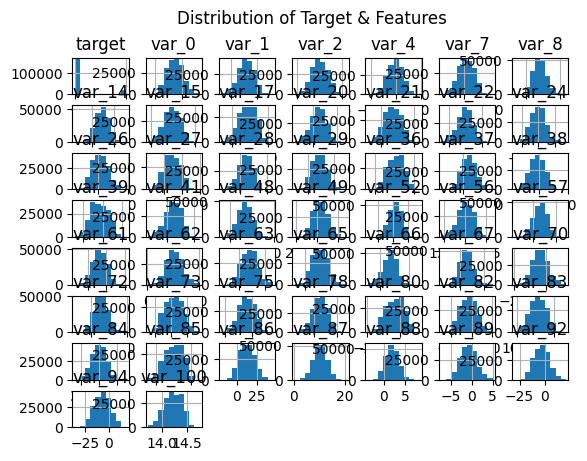

In [148]:
# Display a histogram; shows normal distribution for features (OK for GNB)
df.hist()

plt.suptitle('Distribution of Target & Features')

;

### Correlation: Independence of Features

In [149]:
# Calculate a correlation matrix
corr_mat = features.corr()

corr_mat

,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,var_20,...,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_92,var_94,var_100
var_0,1.000000,-0.000892,-0.000225,-0.000269,-0.001320,0.002949,0.002901,-0.007758,-0.002799,-0.001353,...,-0.004960,-0.005451,-0.000716,0.004577,-0.004664,-0.001088,0.000236,0.001668,0.001837,0.001475
var_1,-0.000892,1.000000,0.006064,-0.000821,0.000783,-0.007127,-0.006180,-0.002585,-0.001663,0.001590,...,0.004265,0.002411,0.001484,-0.003859,-0.000485,0.003141,-0.006188,0.000071,-0.003682,0.003964
var_2,-0.000225,0.006064,1.000000,-0.003427,-0.000108,-0.001809,-0.002786,-0.001177,0.006360,0.004796,...,0.004890,0.002240,0.001980,-0.001161,0.003921,0.002087,-0.004422,-0.003418,-0.001565,0.002418
var_4,-0.000269,-0.000821,-0.003427,1.000000,-0.002750,0.003347,0.001377,-0.004732,-0.001814,-0.000539,...,0.000657,-0.005267,-0.004266,-0.004179,-0.004211,-0.002330,0.000254,0.001090,-0.000468,-0.002807
var_7,-0.001320,0.000783,-0.000108,-0.002750,1.000000,-0.003199,-0.003588,0.002329,0.004282,-0.001971,...,-0.000412,0.003262,0.002574,-0.001824,0.001186,0.002811,0.001306,0.000236,-0.000568,0.004575
var_8,0.002949,-0.007127,-0.001809,0.003347,-0.003199,1.000000,0.003472,-0.003858,-0.002727,-0.003417,...,-0.008394,-0.004254,-0.002446,0.001117,-0.003713,-0.003929,0.003837,0.003422,0.003204,0.000821
var_14,0.002901,-0.006180,-0.002786,0.001377,-0.003588,0.003472,1.000000,-0.007115,-0.004249,-0.001595,...,-0.002214,-0.002179,-0.003054,-0.000160,-0.000504,-0.004046,0.003136,0.005715,0.001501,-0.000106
var_15,-0.007758,-0.002585,-0.001177,-0.004732,0.002329,-0.003858,-0.007115,1.000000,0.002467,0.003584,...,0.000581,0.006633,0.004569,-0.001573,0.003251,0.003066,-0.001541,-0.003719,-0.002825,0.004247
var_17,-0.002799,-0.001663,0.006360,-0.001814,0.004282,-0.002727,-0.004249,0.002467,1.000000,0.001476,...,0.005578,0.001237,0.000210,-0.002714,0.004149,-0.002182,-0.002642,-0.001968,-0.004100,-0.000822
var_20,-0.001353,0.001590,0.004796,-0.000539,-0.001971,-0.003417,-0.001595,0.003584,0.001476,1.000000,...,-0.001476,0.003107,0.001610,0.001186,0.004265,0.001449,-0.004506,-0.003241,-0.000988,0.001734


Text(77.92222222222227, 0.5, 'Features')

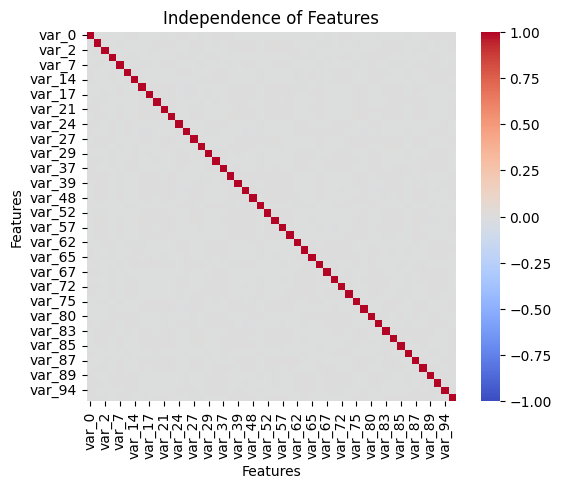

In [150]:
# Heatmap of the correlation matrix to see independence (shows that each feature is perfectly correlated with itself)
sns.heatmap(
    corr_mat,
    square=True,
    annot=False,
    fmt='2f',
    cbar=True,
    cmap='coolwarm',
    vmin=-1,vmax=1
)

plt.title('Independence of Features')
plt.xlabel('Features')
plt.ylabel('Features')

### Create Two Dataframes (Copies, Not Slices)
1. Successful Transactions
1. Unsuccessful Transactions

In [151]:
# Create a dataframe of successful transactions
successful_df = df[df['target'] == 1].copy()

# Create a dataframe of unsuccessful transactions
unsuccessful_df = df[df['target'] == 0].copy()

## Data Processing



#### Description
This section involves building cross validation (CV) models on our unbalanced and balanced data set, then presenting the results by displaying heatmaps of confusion matrixes, classification reports, and accuracy comparisions. The method goes as follows: empty GNB model, setting up a train-test split for our target and features, verifying the train-test-split, fitting (training) the model using training subsets, running predictions using the testing subset, and reporting the accuracy. Insights from the CVs are included here.

Single CV (unbalanced)
- Better at predicting unsuccessful vs. successful
- Low false negative rate when compared to true negatives
- False positive rate is 50% lower than the true positives (33% of the time)

Multi CV (unbalance)
- Accuracy score similar to single CV (unbalanced).

Multi CV (balanced data set)
- Predicts unsuccessful vs. successful transactions evenly
- Predicts incorrectly 25% of the time
- False positive rate is 12.5% of the time
- False negative rate is 12.5% of the time




### Single Cross Validation ( CV )

#### Define an empty Gaussian Naïve Bayes model using Sklearn

In [152]:
# Create an empty GNB model
modelGNB = GaussianNB()

#### Divide the two data sets (target/features) into training and testing subsets, i.e. train-test split.

In [153]:
# Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
     features,
     target,
     test_size=0.25
)

In [154]:
# Verify shape of each data set from Train Test Split
for i in [ X_train, X_test, y_train, y_test ]:
  print(i.shape)
  print(type(i))

(135000, 50)
<class 'pandas.core.frame.DataFrame'>
(45000, 50)
<class 'pandas.core.frame.DataFrame'>
(135000,)
<class 'pandas.core.series.Series'>
(45000,)
<class 'pandas.core.series.Series'>


#### Train ( fit ) the model using the training subset of the dataset.

In [155]:
# Train ( fit ) the model
modelGNB.fit( (X_train), y_train)

GaussianNB()

#### Test the model ( predict ) using the testing subset of the dataset.

In [156]:
# Make predicitons using the model
pred_results = modelGNB.predict(X_test)
pred_results * 1000

array([0., 0., 0., ..., 0., 0., 0.])

#### Calculate and report the accuracy.

In [157]:
# Display accuracy
acc = metrics.accuracy_score( y_test,pred_results )
acc * 100

91.10444444444444

#### Confusion matrix and heatmap

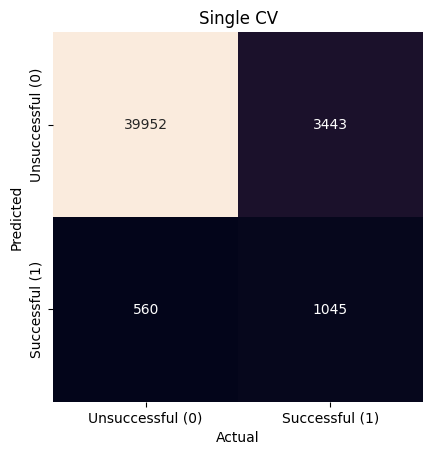

In [158]:
# Display a confusion matrix and heatmap
mat =  metrics.confusion_matrix(
    y_test,
    pred_results
)

sns.heatmap( mat.T,
    square=True,
    annot=True,
    fmt = "d",
    cbar = False,
    xticklabels=['Unsuccessful (0)', 'Successful (1)'],
    yticklabels=['Unsuccessful (0)', 'Successful (1)']
)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Single CV');

#### Classification Report (sklearn.metrics.classification_report).

In [159]:
# Display a classification report
print(metrics.classification_report(y_test, pred_results))

              precision    recall  f1-score   support

         0.0       0.92      0.99      0.95     40512
         1.0       0.65      0.23      0.34      4488

    accuracy                           0.91     45000
   macro avg       0.79      0.61      0.65     45000
weighted avg       0.89      0.91      0.89     45000



### Multiple Cross-Validation (CV)

In [160]:
# Multiple CV loop
n = 100
results = np.zeros(n)

for i in range(n):
    X_train, X_test, y_train, y_test = train_test_split(
        features, target, test_size=0.25, random_state=None
    )

    # Create an empty GNB model
    modelGNB = GaussianNB()

    # Train ( fit ) the model
    modelGNB.fit( (X_train), y_train)

    # Make predicitons using the model
    pred_results = modelGNB.predict(X_test)

    # calculate the accuracy
    results[i] = metrics.accuracy_score(y_test, pred_results)

results

array([0.91026667, 0.91033333, 0.91057778, 0.91217778, 0.91284444,
       0.91077778, 0.91308889, 0.91064444, 0.91097778, 0.90962222,
       0.90957778, 0.91126667, 0.90891111, 0.91184444, 0.90866667,
       0.91282222, 0.91326667, 0.90924444, 0.91117778, 0.91215556,
       0.91166667, 0.91028889, 0.91122222, 0.91226667, 0.91046667,
       0.91162222, 0.91173333, 0.9112    , 0.90895556, 0.91102222,
       0.91006667, 0.91006667, 0.91144444, 0.91126667, 0.90957778,
       0.91226667, 0.91144444, 0.91035556, 0.91224444, 0.91077778,
       0.91133333, 0.9122    , 0.91075556, 0.9108    , 0.91035556,
       0.91233333, 0.9118    , 0.90982222, 0.90942222, 0.90957778,
       0.91082222, 0.91011111, 0.90982222, 0.9118    , 0.91231111,
       0.91033333, 0.90975556, 0.91157778, 0.91068889, 0.90993333,
       0.91048889, 0.91144444, 0.91111111, 0.91224444, 0.91146667,
       0.91128889, 0.91144444, 0.91173333, 0.91015556, 0.91206667,
       0.9124    , 0.90993333, 0.91013333, 0.90986667, 0.91071

#### Classification Report

In [161]:
# Display a classification report
print(metrics.classification_report(y_test, pred_results))

              precision    recall  f1-score   support

         0.0       0.92      0.99      0.95     40480
         1.0       0.68      0.23      0.34      4520

    accuracy                           0.91     45000
   macro avg       0.80      0.61      0.65     45000
weighted avg       0.90      0.91      0.89     45000



### Accuracy Comparison (single CV vs. multi CV)

In [162]:
# Compare the accuracies by creating variables for each
acc_single_cv = acc
acc_multi_cv = results[i]

display('Single CV:', acc_single_cv)
display('Multi CV:', acc_multi_cv)

'Single CV:'

0.9110444444444444

'Multi CV:'

np.float64(0.9119555555555555)

### Balance Dataset

The training data is very skewed towards non-successful transactions (about 90% of the training data has ‘target’==0).

Remove enough non-successful transaction rows so that your remaining training data is 50%/50% split between successful and non-successful transactions.

In [163]:
# Display value counts of the target
df['target'].value_counts()

,count
target,
0.0,161960
1.0,18040


In [164]:
# Place minority class in one dataframe (done above)
successful_df

,target,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,...,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_92,var_94,var_100
57,1.0,8.9078,12.1321,9.4707,-5.8102,0.4521,7.1264,15.6935,2.6980,4.3336,...,11.2059,4.0237,5.8905,12.4865,10.1419,2.3370,-3.1553,-12.6928,-3.0833,14.1895
125,1.0,6.2143,20.0990,23.5009,-0.8917,-3.9167,6.6863,21.4162,2.8672,6.4550,...,10.8110,3.9190,7.4971,35.7428,9.6149,2.2257,-0.5949,-9.4101,-15.6555,14.4514
151,1.0,8.9083,12.1117,18.0359,-4.9628,10.1135,6.8962,11.4553,2.6735,2.1990,...,11.6326,3.9193,5.0366,37.1453,17.0341,0.9987,-3.0163,-1.5409,-7.6389,14.1725
155,1.0,6.5612,13.9638,5.1980,12.1092,8.4874,6.4781,16.9541,2.0573,5.5008,...,11.2981,4.1316,7.2193,-1.8139,1.8190,2.5720,0.6780,6.4045,1.1754,14.1347
302,1.0,4.4616,9.7572,12.9317,7.6485,0.6382,5.8025,22.4577,3.0906,16.2501,...,11.5449,4.0001,9.0639,11.8805,9.4678,1.0561,-0.2107,9.8815,-2.9328,14.0933
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1049783,1.0,3.1286,15.0751,21.3962,11.3161,-10.0493,6.3525,25.4931,2.6605,7.2691,...,10.9172,4.1120,4.6540,9.1151,7.8918,2.5714,1.0304,5.2623,-0.6030,14.1993
1049818,1.0,15.2934,17.5721,5.8949,-4.0233,5.8840,7.3892,11.3932,2.7062,6.9666,...,11.1665,3.9652,7.4879,-7.9060,10.7256,0.8941,-3.5967,6.3976,0.5778,14.5067
1049978,1.0,7.4751,17.0314,5.0834,-1.5220,-2.4913,6.7953,10.7764,2.9049,2.6145,...,11.6605,3.6716,8.5965,19.2145,8.2747,4.0945,-3.0127,2.9477,-2.3696,14.4122
1049983,1.0,5.2746,14.4095,17.7709,-2.9855,-0.8515,6.5097,11.5599,2.9677,0.0507,...,11.8870,3.7776,6.9876,3.3482,9.7469,-0.3425,-2.5684,14.5286,-5.4146,14.4388


In [165]:
# Put majority class into its own dataframe (done above)
unsuccessful_df

,target,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,...,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_92,var_94,var_100
3,0.0,4.6739,22.3915,15.6015,0.0464,-1.9254,6.4760,21.6435,2.8817,11.6975,...,11.8011,3.9677,9.5382,-8.4394,5.5043,2.2732,1.6362,11.1077,-12.6465,14.0618
5,0.0,14.6962,18.3383,17.4788,-9.1355,-6.4882,6.0821,11.7476,2.2225,7.2218,...,11.8294,3.8887,8.8591,6.1482,8.5833,2.8432,1.8434,-2.0111,-3.6166,14.4520
11,0.0,4.4949,14.4142,13.2219,4.9140,4.0501,5.8144,18.7136,3.4990,4.2892,...,11.7464,4.0017,5.8179,10.4951,12.4494,2.8009,0.3394,13.9424,-15.5776,14.1222
15,0.0,4.9657,16.2867,17.9579,0.6017,-5.4904,6.6670,8.1019,2.8910,8.2374,...,11.5481,3.9809,8.2247,21.2257,6.9931,3.3939,-2.3905,3.7943,5.6184,14.0619
19,0.0,9.4287,18.7822,10.7630,-0.7532,8.8477,6.8045,19.0069,3.2771,12.6446,...,10.8981,4.1808,9.4220,1.8563,10.5738,1.2409,-1.3888,-5.6677,-1.8961,14.0275
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1049988,0.0,10.7453,13.3217,15.4001,4.0421,1.3116,6.3990,13.9387,2.9627,13.6450,...,11.6062,3.9162,9.7054,15.2405,10.6480,0.5372,0.4014,4.8258,-8.2380,14.0328
1049990,0.0,7.9632,20.4650,10.7295,2.9322,5.0267,7.1953,10.0695,3.0732,11.0135,...,12.1000,4.2019,7.1249,14.6591,10.2705,3.5833,2.5588,10.4219,-19.7158,14.0582
1049993,0.0,5.0862,14.4785,17.3709,-2.4732,-2.5987,6.6798,3.0420,2.4057,18.2729,...,10.9960,3.9637,8.0217,11.0449,9.3100,1.0545,-2.8770,-2.8052,-13.7290,14.3794
1049997,0.0,8.9941,13.4127,3.9567,3.5744,1.6614,6.1486,12.0996,2.5439,10.2936,...,10.5067,4.0642,8.3381,17.9081,12.3357,2.6530,-1.2359,2.0836,-18.6168,14.0689


In [166]:
# Create downsample of majority class in another data frame
majority_downsampled = unsuccessful_df.sample(
    n=len(successful_df),
    random_state=42
)

# Display the downsample to verify
print("Minority class:")
print(successful_df['target'].value_counts())

print("Downsampled majority class:")
print(majority_downsampled['target'].value_counts())

Minority class:
target
1.0    18040
Name: count, dtype: int64
Downsampled majority class:
target
0.0    18040
Name: count, dtype: int64


In [167]:
# Combine the dataframes
balanced_df = pd.concat([successful_df, majority_downsampled])

# Reset the index
balanced_df = balanced_df.reset_index(drop=True)

In [168]:
# Verify target counts are now equal
balanced_df['target'].value_counts()

,count
target,
1.0,18040
0.0,18040


#### Backup #3

In [169]:
# Create 3rd backup
df_bak_3 = df.copy()

In [170]:
# Restore from backup
df = df_bak_3.copy()

#### Repeat Multi Cross-Validation

In [171]:
# Split data frame into target and features using balanced dataset
target_col = 'target'
target_balanced_df = balanced_df[ target_col]
features_balanced_df = balanced_df.drop(columns=[target_col])

In [172]:
# Verify the balanced target
target_balanced_df

,target
0,1.0
1,1.0
2,1.0
3,1.0
4,1.0
...,...
36075,0.0
36076,0.0
36077,0.0
36078,0.0


In [173]:
# Verify the features
features_balanced_df

,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,var_20,...,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_92,var_94,var_100
0,8.9078,12.1321,9.4707,-5.8102,0.4521,7.1264,15.6935,2.6980,4.3336,12.5243,...,11.2059,4.0237,5.8905,12.4865,10.1419,2.3370,-3.1553,-12.6928,-3.0833,14.1895
1,6.2143,20.0990,23.5009,-0.8917,-3.9167,6.6863,21.4162,2.8672,6.4550,16.3479,...,10.8110,3.9190,7.4971,35.7428,9.6149,2.2257,-0.5949,-9.4101,-15.6555,14.4514
2,8.9083,12.1117,18.0359,-4.9628,10.1135,6.8962,11.4553,2.6735,2.1990,11.1778,...,11.6326,3.9193,5.0366,37.1453,17.0341,0.9987,-3.0163,-1.5409,-7.6389,14.1725
3,6.5612,13.9638,5.1980,12.1092,8.4874,6.4781,16.9541,2.0573,5.5008,0.3052,...,11.2981,4.1316,7.2193,-1.8139,1.8190,2.5720,0.6780,6.4045,1.1754,14.1347
4,4.4616,9.7572,12.9317,7.6485,0.6382,5.8025,22.4577,3.0906,16.2501,7.3399,...,11.5449,4.0001,9.0639,11.8805,9.4678,1.0561,-0.2107,9.8815,-2.9328,14.0933
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36075,4.4165,14.1108,16.9036,-1.7004,0.5204,6.5962,-2.6199,3.4255,0.1414,19.1131,...,11.4631,3.8506,9.0249,20.1304,11.3339,0.5109,3.3331,-13.1584,4.6673,14.4395
36076,9.6312,17.9872,6.1934,-4.5551,5.6778,7.0958,8.8347,2.8895,2.4021,-2.5986,...,10.8018,4.2457,8.4013,6.5742,13.5109,2.7851,-0.1141,-8.5076,-18.8957,14.2713
36077,4.6518,12.6792,19.3345,-5.9933,1.5722,6.7321,18.5658,3.2414,11.3328,-5.9847,...,11.1230,4.0996,7.5840,6.1360,10.7843,3.0418,-0.4006,-9.1780,2.4831,13.9453
36078,5.5259,17.4647,19.3796,7.8173,-1.7046,7.8236,19.1841,3.0881,16.8589,4.4127,...,11.1961,4.0940,6.2651,-10.3256,12.5128,2.9950,-2.7132,-14.1962,-11.4152,14.3034


In [174]:
# Multiple CV loop
n = 100
balanced_df_results = np.zeros(n)

for i in range(n):
    X_train, X_test, y_train, y_test = train_test_split(
        features_balanced_df, target_balanced_df, test_size=0.25, random_state=None
    )

   # Create an empty GNB model
    modelGNB = GaussianNB()

    # Train ( fit ) the model
    modelGNB.fit( (X_train), y_train)

    # Make predicitons using the model
    pred_results = modelGNB.predict(X_test)

    # calculate the accuracy
    balanced_df_results[i] = metrics.accuracy_score(y_test, pred_results)

balanced_df_results

array([0.75931264, 0.75133038, 0.75133038, 0.75354767, 0.75077605,
       0.75321508, 0.75055432, 0.75299335, 0.74988914, 0.76019956,
       0.75487805, 0.75620843, 0.75277162, 0.74778271, 0.75266075,
       0.7481153 , 0.75432373, 0.75875831, 0.74889135, 0.75731707,
       0.74955654, 0.75055432, 0.7556541 , 0.7559867 , 0.7518847 ,
       0.74223947, 0.74977827, 0.75909091, 0.75088692, 0.7575388 ,
       0.75332594, 0.75576497, 0.74977827, 0.75288248, 0.75576497,
       0.75133038, 0.7594235 , 0.75909091, 0.75044346, 0.74778271,
       0.75521064, 0.75886918, 0.754102  , 0.75166297, 0.75288248,
       0.75742794, 0.74855876, 0.75343681, 0.75177384, 0.74767184,
       0.75299335, 0.76053215, 0.75953437, 0.75731707, 0.74323725,
       0.754102  , 0.74966741, 0.75543237, 0.74789357, 0.74988914,
       0.75476718, 0.76718404, 0.75532151, 0.75133038, 0.75875831,
       0.75321508, 0.75022173, 0.75920177, 0.75365854, 0.74423503,
       0.75044346, 0.75654102, 0.75266075, 0.74944568, 0.75066

#### Mean accuracy for balanced dataset

In [175]:
# Report what your mean accuracy for this balanced data set
display(balanced_df_results[i])

np.float64(0.7522172949002217)

In [176]:
# Display a classification report
print(metrics.classification_report(y_test, pred_results))

              precision    recall  f1-score   support

         0.0       0.75      0.77      0.76      4513
         1.0       0.76      0.74      0.75      4507

    accuracy                           0.75      9020
   macro avg       0.75      0.75      0.75      9020
weighted avg       0.75      0.75      0.75      9020



#### Histogram of the accuracy scores

''

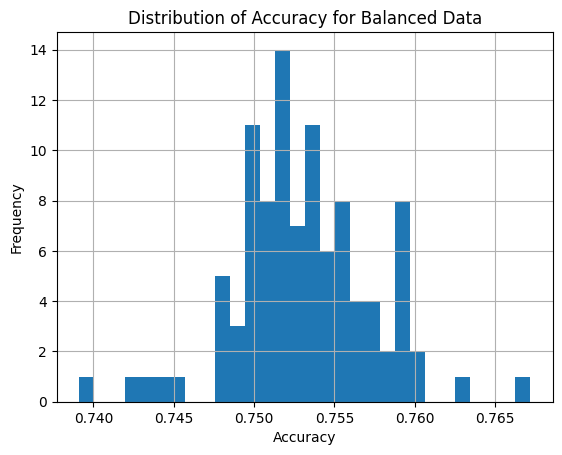

In [177]:
# Display a histogram of the balanced dataset
pd.Series(balanced_df_results).hist(bins=30)

plt.title('Distribution of Accuracy for Balanced Data')
plt.xlabel('Accuracy')
plt.ylabel('Frequency')
;

What do you notice about the distribution of accuracy scores?

There is a positive skew.

#### Confusion Matrix and Heatmap

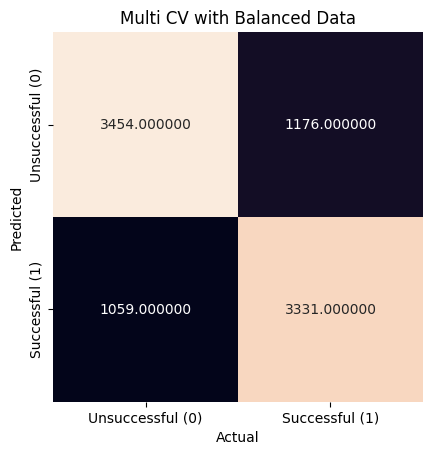

In [178]:
# Displaly a confusion matrix and heatmap
mat =  metrics.confusion_matrix(
    y_test,
    pred_results,
)

sns.heatmap( mat.T,
    square=True,
    annot=True,
    fmt = "2f",
    cbar = False,
    xticklabels=['Unsuccessful (0)', 'Successful (1)'],
    yticklabels=['Unsuccessful (0)', 'Successful (1)']
)
plt.title('Multi CV with Balanced Data')
plt.xlabel('Actual')
plt.ylabel('Predicted');

#### Classification Report

In [179]:
# Display a classification report
print(metrics.classification_report(y_test, pred_results))

              precision    recall  f1-score   support

         0.0       0.75      0.77      0.76      4513
         1.0       0.76      0.74      0.75      4507

    accuracy                           0.75      9020
   macro avg       0.75      0.75      0.75      9020
weighted avg       0.75      0.75      0.75      9020



What do you notice? That is, how do the different metrics compare to each other?

## Data Visualization/Communication of Results


#### Description
This section displays a histogram of the results after cleaning, balancing and comparing insights from CVs. Below, I chose to display a frequency distribution of the accuracy scores from running a multi CV with the balanced data set because it shows a predictable pattern. It more evenly predicts a successful vs. unsuccessful transaction despite a lower mean accuracy.

### Data Visualization

''

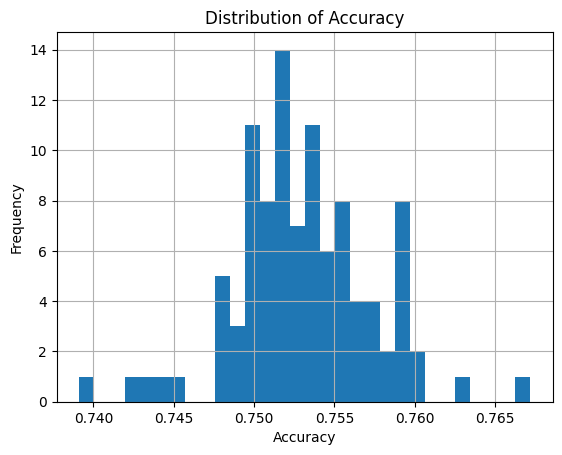

In [180]:
# Display a histagram of the results
pd.Series(balanced_df_results).hist(bins=30)

plt.title('Distribution of Accuracy')
plt.xlabel('Accuracy')
plt.ylabel('Frequency')
;

## Communication of Results



#### Description
This section contains my conclusions (insights from running our models before and after balancing the dataset). It also contains recommendations for future work including using alternative metrics and alternative classification models.

### Conclusion

- Accuracy alone doesn’t necessarily mean model is good at identifying successful transactions
- Higher accuracy may indicate the model is good at predicting the majority class (unsuccessful transactions)
- Accuracy dropped from 91% to 75% after balancing the data set
- Balanced data set provides more even representation
- Single CV not great at predicting a successful transaction.
- Multi CV more evenly predicts a successful vs. unsuccessful transaction despite a lower mean accuracy.

### Future work

Alternative metrics besides accuracy

- Precision, recall, and F1-score

Alternative classification models

- Predicts successful and unsuccessful transactions more effectively
